In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"../../Dataset/NF-UNSW-NB15-v2.csv", low_memory=False)
df.head(5)

,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,59.166.0.5,1305,149.171.126.8,21,6,1.0,9,1,193,3,...,0,7240,0,0,0,0,0,331.0,0,Benign
1,59.166.0.5,1305,149.171.126.8,21,6,1.0,261,5,469,7,...,8688,8688,18944,74,0,0,0,230.0,0,Benign
2,59.166.0.5,1305,149.171.126.8,21,6,1.0,481,9,750,11,...,10136,10136,33792,132,0,0,0,229.0,0,Benign
3,59.166.0.5,1305,149.171.126.8,21,6,1.0,701,13,1054,15,...,11584,11584,48640,190,0,0,0,125.0,0,Benign
4,59.166.0.5,1305,149.171.126.8,21,6,1.0,1031,19,1474,21,...,14480,13032,64256,251,0,0,0,230.0,0,Benign


In [3]:
df.shape

(2390275, 45)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2390275 entries, 0 to 2390274
Data columns (total 45 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   IPV4_SRC_ADDR                object 
 1   L4_SRC_PORT                  int64  
 2   IPV4_DST_ADDR                object 
 3   L4_DST_PORT                  int64  
 4   PROTOCOL                     int64  
 5   L7_PROTO                     float64
 6   IN_BYTES                     int64  
 7   IN_PKTS                      int64  
 8   OUT_BYTES                    int64  
 9   OUT_PKTS                     int64  
 10  TCP_FLAGS                    int64  
 11  CLIENT_TCP_FLAGS             int64  
 12  SERVER_TCP_FLAGS             int64  
 13  FLOW_DURATION_MILLISECONDS   int64  
 14  DURATION_IN                  int64  
 15  DURATION_OUT                 int64  
 16  MIN_TTL                      int64  
 17  MAX_TTL                      int64  
 18  LONGEST_FLOW_PKT             int64  
 19  

In [5]:
df.describe()

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label
count,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,...,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06
mean,3.254961e+04,1.142309e+04,9.151913e+00,3.038721e+00,4.621664e+03,3.603686e+01,3.526565e+04,4.570363e+01,1.989969e+01,1.961149e+01,...,2.382468e+01,1.738763e+04,1.222160e+04,1.894443e+04,7.400138e+01,4.949701e+03,2.970099e+00,2.725637e+04,3.765351e+01,3.976655e-02
std,1.916212e+04,1.853915e+04,1.101865e+01,1.358876e+01,7.021409e+04,7.995682e+01,1.565155e+05,1.174495e+02,1.113381e+01,1.105082e+01,...,1.114788e+02,1.693017e+04,1.097592e+04,2.037120e+04,7.957477e+01,1.378088e+04,1.240340e+02,8.958054e+06,8.430295e+01,1.954103e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.583100e+04,2.500000e+01,6.000000e+00,0.000000e+00,4.810000e+02,4.000000e+00,3.120000e+02,4.000000e+00,1.900000e+01,1.900000e+01,...,0.000000e+00,0.000000e+00,5.792000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,3.265000e+04,8.000000e+01,6.000000e+00,0.000000e+00,1.684000e+03,1.800000e+01,2.456000e+03,1.800000e+01,2.700000e+01,2.700000e+01,...,0.000000e+00,1.448000e+04,1.303200e+04,1.100800e+04,4.300000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.907600e+04,1.588700e+04,6.000000e+00,1.000000e+00,3.286000e+03,4.400000e+01,1.496800e+04,4.400000e+01,2.700000e+01,2.700000e+01,...,1.200000e+01,2.461600e+04,1.448000e+04,3.379200e+04,1.320000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,6.553500e+04,2.550000e+02,2.480000e+02,3.024141e+07,2.289400e+04,1.465852e+07,1.107800e+04,3.100000e+01,3.100000e+01,...,1.967600e+04,6.553300e+04,6.553100e+04,6.531700e+04,2.550000e+02,6.553500e+04,5.593700e+04,4.283358e+09,5.010000e+02,1.000000e+00


In [6]:
df.isnull().sum()

IPV4_SRC_ADDR                  0
L4_SRC_PORT                    0
IPV4_DST_ADDR                  0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST_AVG_THROUGHPUT      0
DST_TO_SRC_AVG_THROUGHPUT      0
NUM_PKTS_U

df.duplicated().sum()

## display count

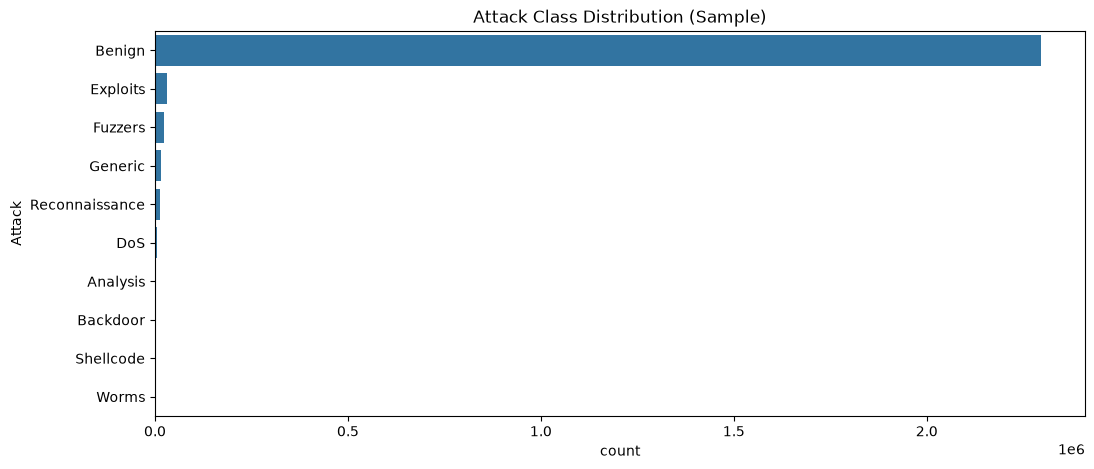

Attack
Benign            96.02
Exploits           1.32
Fuzzers            0.93
Generic            0.69
Reconnaissance     0.53
DoS                0.24
Analysis           0.10
Backdoor           0.09
Shellcode          0.06
Worms              0.01
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(12,5))
order = df["Attack"].value_counts().index
sns.countplot(data=df, y="Attack", order=order)
plt.title("Attack Class Distribution (Sample)")
plt.show()

print(df["Attack"].value_counts(normalize=True).mul(100).round(2))

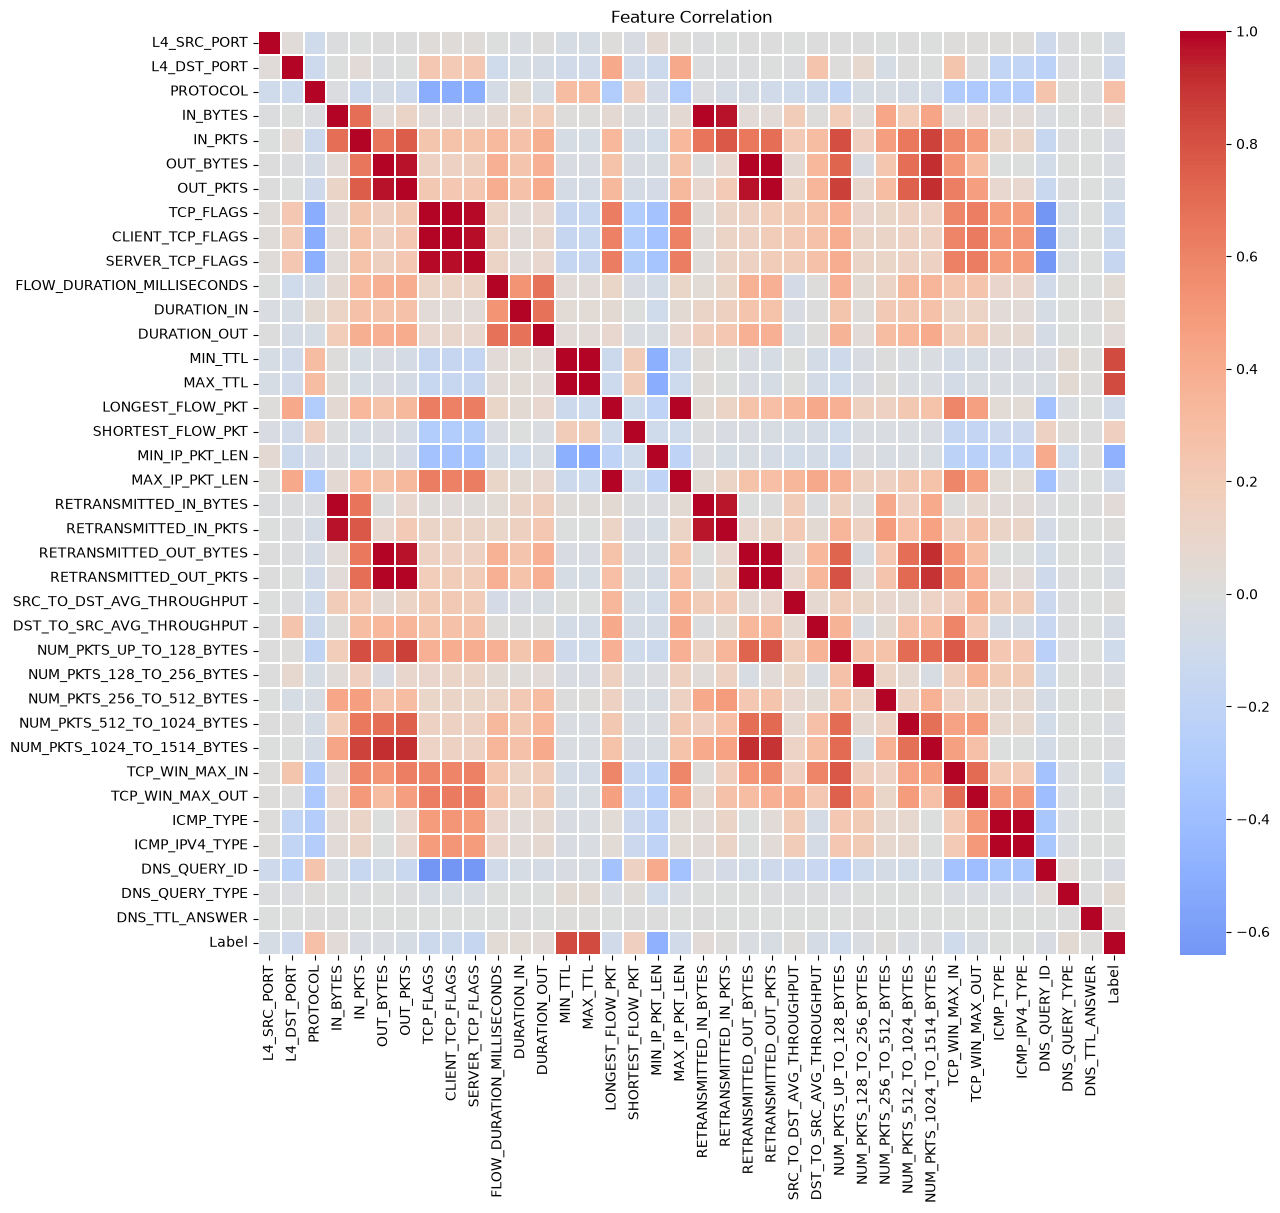

In [8]:
num_cols = df.select_dtypes(include=["int64","float32"]).columns.tolist()
# remove Label if present
corr = df[num_cols].corr()
plt.figure(figsize=(14,12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature Correlation")
plt.show()

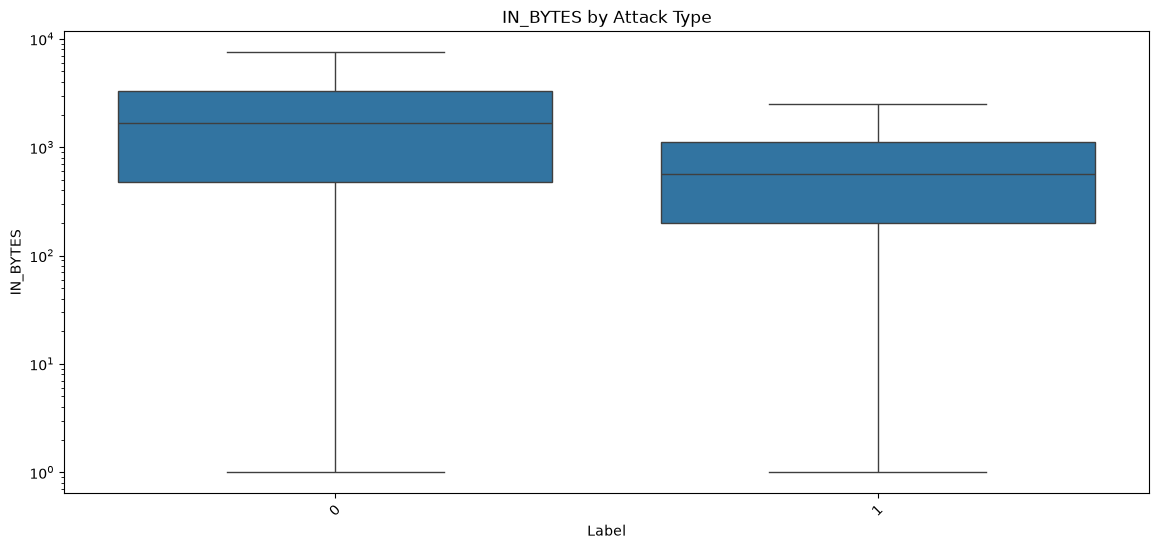

In [9]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Label", y="IN_BYTES", showfliers=False)
plt.xticks(rotation=45)
plt.yscale("log")
plt.title("IN_BYTES by Attack Type")
plt.show()

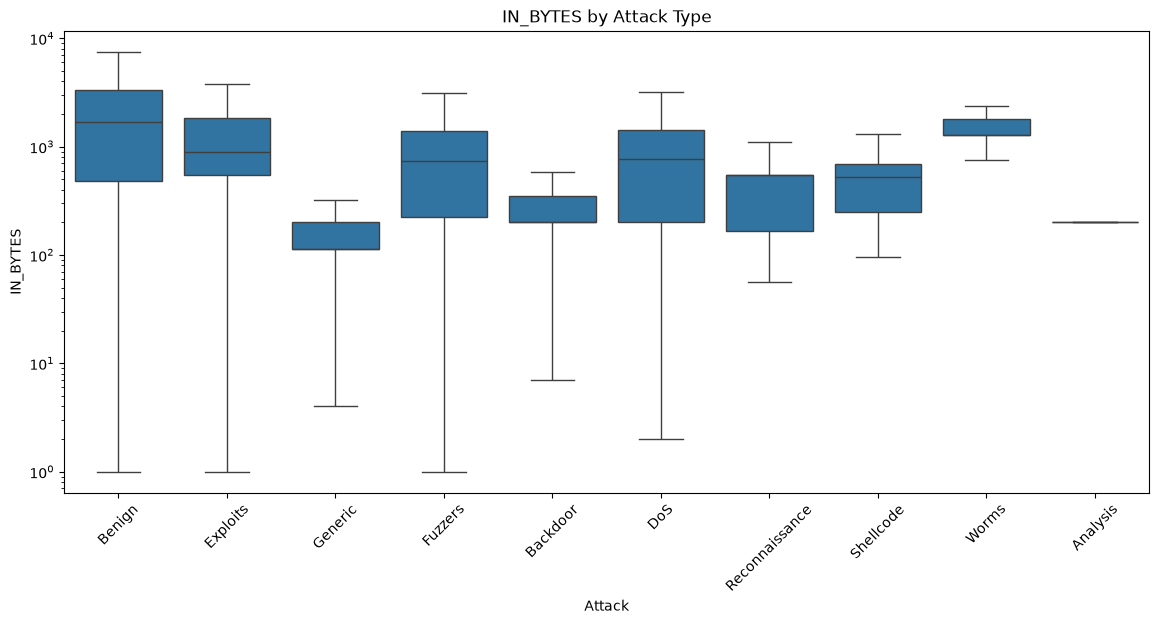

In [10]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Attack", y="IN_BYTES", showfliers=False)
plt.xticks(rotation=45)
plt.yscale("log")
plt.title("IN_BYTES by Attack Type")
plt.show()

### drop column

In [11]:
drop_cols = [
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'L4_SRC_PORT',
    'DNS_QUERY_ID'         # keep 'Label' as binary target
]
# Optionally also:
# drop_cols += ['L4_DST_PORT']          # if you don't bin it
# drop_cols += ['CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS']  # if corr with TCP_FLAGS > 0.95

df.drop(columns=drop_cols,inplace=True)
# y = df['Label']   # binary 0/1 target

In [12]:
df.shape

(2390275, 41)

## Drop column zero-varience

In [13]:
# 1. Near-zero-variance columns (e.g., a column that's 99.9% one value)
from sklearn.feature_selection import VarianceThreshold
near_zero = [c for c in df.columns if df[c].value_counts(normalize=True).iloc[0] > 0.999]

# 2. Highly correlated pairs (|r| > 0.95) — keep one
corr = df.select_dtypes('number').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_drop = [c for c in upper.columns if any(upper[c] > 0.95)]

# 3. All-NaN or all-zero columns
all_zero_or_nan = [c for c in df.columns if (df[c].fillna(-1) == df[c].iloc[0]).all()]

In [14]:
# 1. Select only numeric columns (correlation requires numbers)
numeric_df = df.select_dtypes(include=['number'])

# 2. Calculate correlation of all numeric columns with 'Label'
# We drop 'Label' itself from the result to avoid a perfect 1.0 correlation
corr_with_label = numeric_df.corr()['Label'].drop('Label')

# 3. Sort by absolute value to see the strongest relationships first
sorted_corr = corr_with_label.abs().sort_values(ascending=False)

print("--- Correlation of Features with 'Label' ---")
print(sorted_corr)

--- Correlation of Features with 'Label' ---
MIN_TTL                        0.824906
MAX_TTL                        0.824857
MIN_IP_PKT_LEN                 0.484103
PROTOCOL                       0.280589
SHORTEST_FLOW_PKT              0.159197
SERVER_TCP_FLAGS               0.155205
TCP_FLAGS                      0.121476
CLIENT_TCP_FLAGS               0.117141
L4_DST_PORT                    0.107090
NUM_PKTS_UP_TO_128_BYTES       0.099058
TCP_WIN_MAX_IN                 0.092124
MAX_IP_PKT_LEN                 0.086539
LONGEST_FLOW_PKT               0.086539
DST_TO_SRC_AVG_THROUGHPUT      0.057337
DNS_QUERY_TYPE                 0.054415
OUT_PKTS                       0.050564
FTP_COMMAND_RET_CODE           0.044619
TCP_WIN_MAX_OUT                0.040457
RETRANSMITTED_OUT_PKTS         0.039813
DURATION_IN                    0.038765
FLOW_DURATION_MILLISECONDS     0.038436
IN_PKTS                        0.038428
RETRANSMITTED_IN_BYTES         0.034925
DURATION_OUT                   0.03

In [15]:
df.shape

(2390275, 41)

In [16]:
# Check if every single row matches perfectly
are_identical = df['MAX_IP_PKT_LEN'].equals(df['LONGEST_FLOW_PKT'])
print(f"Are the columns exact duplicates? {are_identical}")

# Alternatively, count how many rows are different
differences = (df['MAX_IP_PKT_LEN'] != df['LONGEST_FLOW_PKT']).sum()
print(f"Number of rows where they differ: {differences} out of {len(df)}")


Are the columns exact duplicates? True
Number of rows where they differ: 0 out of 2390275


In [17]:
# List of columns to drop based on redundancy and low correlation
cols_to_drop = [
    'LONGEST_FLOW_PKT',            # Redundant with MAX_IP_PKT_LEN
    'ICMP_TYPE',                   # Near-zero correlation
    'ICMP_IPV4_TYPE',              # Near-zero correlation
    'DST_TO_SRC_SECOND_BYTES',     # Near-zero correlation
    'SRC_TO_DST_SECOND_BYTES'      # Near-zero correlation
]

# Drop the columns from your DataFrame (replace 'df' with your variable name)
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')


## Skewness check

In [18]:
# 1. Isolate numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns

# 2. Calculate skewness (Pandas handles this efficiently even on large datasets)
skewness_values = df[numeric_cols].skew().sort_values(ascending=False)

# 3. Display as a clean DataFrame
skew_df = pd.DataFrame({'Column': skewness_values.index, 'Skewness': skewness_values.values})
print("--- Skewness of All Numeric Columns ---")
print(skew_df.to_string(index=False))

--- Skewness of All Numeric Columns ---
                     Column   Skewness
             DNS_TTL_ANSWER 369.837869
             DNS_QUERY_TYPE 274.694910
     RETRANSMITTED_IN_BYTES 259.768642
                   IN_BYTES 259.039324
      RETRANSMITTED_IN_PKTS 233.567566
  NUM_PKTS_256_TO_512_BYTES 217.507449
                    IN_PKTS  75.942572
                DURATION_IN  31.090211
NUM_PKTS_1024_TO_1514_BYTES  26.702091
               DURATION_OUT  25.802879
          SHORTEST_FLOW_PKT  23.424087
  SRC_TO_DST_AVG_THROUGHPUT  16.918234
                   PROTOCOL  13.531138
     RETRANSMITTED_OUT_PKTS  13.097212
    RETRANSMITTED_OUT_BYTES  12.160321
                  OUT_BYTES  12.119828
  NUM_PKTS_128_TO_256_BYTES  11.862865
                   OUT_PKTS  11.558621
 NUM_PKTS_512_TO_1024_BYTES  11.545945
  DST_TO_SRC_AVG_THROUGHPUT   8.769573
                   L7_PROTO   6.458733
   NUM_PKTS_UP_TO_128_BYTES   5.228700
                    MIN_TTL   4.996356
                    MAX_

In [19]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# 1. Define target and categorical integer ID columns to EXCLUDE from log1p
exclude_from_log = [
    "Label", "Attack", "target",          # Targets
    "PROTOCOL", "L7_PROTO",               # Protocol IDs
    "L4_SRC_PORT", "L4_DST_PORT",         # Port numbers
    "DNS_QUERY_TYPE", "DNS_QUERY_ID",     # DNS codes
    "FTP_COMMAND_RET_CODE",               # FTP status codes
    "ICMP_TYPE", "ICMP_IPV4_TYPE",        # ICMP codes
    "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS" # Bitmask flags
]

# 2. Get all numeric columns (excluding targets) for scaling later
all_numeric_cols = df.select_dtypes(include=[np.number]).columns.drop(
    ["Label", "Attack", "target"], errors="ignore"
)

# 3. Sanitize Infinity and NaN in-place before math operations
df[all_numeric_cols] = df[all_numeric_cols].replace([np.inf, -np.inf], np.nan)
df[all_numeric_cols] = df[all_numeric_cols].fillna(0)

# 4. Filter candidate columns for log1p (Numeric minus Categorical IDs)
log_candidates = [col for col in all_numeric_cols if col not in exclude_from_log]

# 5. Select ONLY columns with Skewness > 2.0
skewness = df[log_candidates].skew()
skewed_cols = skewness[skewness > 2.0].index.tolist()

print(f"Applying log1p to {len(skewed_cols)} skewed continuous columns...")

# 6. Apply log1p safely in-place (clip negatives to 0 instead of raising ValueError)
df[skewed_cols] = np.log1p(df[skewed_cols].clip(lower=0))

# 7. Apply RobustScaler in-place across numeric features
scaler = RobustScaler()
df[all_numeric_cols] = scaler.fit_transform(df[all_numeric_cols])

print("In-place log1p transformation and RobustScaler applied successfully!")
print(df.head())

Applying log1p to 22 skewed continuous columns...
In-place log1p transformation and RobustScaler applied successfully!
   L4_DST_PORT  PROTOCOL  L7_PROTO  IN_BYTES   IN_PKTS  OUT_BYTES  OUT_PKTS  \
0     -0.00372       0.0       1.0 -2.670576 -1.024607  -0.656449 -0.709142   
1     -0.00372       0.0       1.0 -0.969471 -0.524607  -0.427653 -0.393677   
2     -0.00372       0.0       1.0 -0.651935 -0.292120  -0.306472 -0.209142   
3     -0.00372       0.0       1.0 -0.456086 -0.138985  -0.218589 -0.078212   
4     -0.00372       0.0       1.0 -0.255376  0.023345  -0.131940  0.066722   

   TCP_FLAGS  CLIENT_TCP_FLAGS  SERVER_TCP_FLAGS  ...  \
0     -0.375            -0.375         -1.000000  ...   
1     -0.375            -0.375         -0.272727  ...   
2     -0.375            -0.375         -0.272727  ...   
3     -0.375            -0.375         -0.272727  ...   
4     -0.375            -0.375         -0.272727  ...   

   NUM_PKTS_256_TO_512_BYTES  NUM_PKTS_512_TO_1024_BYTES  \
0  

In [20]:
# Count occurrences of 0 and 1 in Label
# print(df["Label"].value_counts().reindex([0, 1], fill_value=0))

# Count and percentage
print("\nLabel distribution:")
print(df["Label"].value_counts(normalize=False).reindex([0, 1], fill_value=0))

print("\nPercentage distribution:")
print(
    (df["Label"].value_counts(normalize=True) * 100)
    .reindex([0, 1], fill_value=0)
    .round(2)
)


Label distribution:
Label
0    2295222
1      95053
Name: count, dtype: int64

Percentage distribution:
Label
0    96.02
1     3.98
Name: proportion, dtype: float64


In [21]:
print("--- Post-Transformation Skewness ---")
print(df[skewed_cols].skew().sort_values(ascending=False))

--- Post-Transformation Skewness ---
SHORTEST_FLOW_PKT              5.890080
DURATION_IN                    3.920856
DURATION_OUT                   3.900447
FLOW_DURATION_MILLISECONDS     3.693219
NUM_PKTS_512_TO_1024_BYTES     2.713706
DNS_TTL_ANSWER                 2.364458
NUM_PKTS_128_TO_256_BYTES      1.949247
NUM_PKTS_256_TO_512_BYTES      1.213257
NUM_PKTS_1024_TO_1514_BYTES    1.157204
MIN_TTL                        0.588083
RETRANSMITTED_OUT_PKTS         0.552621
MAX_TTL                        0.448970
OUT_PKTS                       0.131104
RETRANSMITTED_IN_PKTS          0.114404
SRC_TO_DST_AVG_THROUGHPUT      0.062041
IN_PKTS                        0.060264
NUM_PKTS_UP_TO_128_BYTES      -0.202307
IN_BYTES                      -0.286468
OUT_BYTES                     -0.288009
RETRANSMITTED_OUT_BYTES       -0.399048
RETRANSMITTED_IN_BYTES        -0.576770
DST_TO_SRC_AVG_THROUGHPUT     -2.878889
dtype: float64


In [22]:
np.isinf(df.select_dtypes(include=[np.number])).values.sum()

np.int64(0)

In [23]:
# If you still have the raw df with string Attack labels:
counts = df['Attack'].value_counts()
print(counts)

Attack
Benign            2295222
Exploits            31551
Fuzzers             22310
Generic             16560
Reconnaissance      12779
DoS                  5794
Analysis             2299
Backdoor             2169
Shellcode            1427
Worms                 164
Name: count, dtype: int64


In [24]:
df.shape

(2390275, 36)

In [25]:
# df.drop(columns=['Label'], inplace=True)

In [26]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import BorderlineSMOTE, SMOTE

# ============================================================
# STEP 0: Pre-Clean Raw Data (Drop IPs, Infinity, & Duplicates)
# ============================================================
print("Initial raw shape:", df.shape)

# 1. Strip whitespace from column names and Attack strings
df.columns = df.columns.str.strip()
target_col = "Attack"
if target_col not in df.columns:
    raise ValueError("The 'Attack' column is missing.")

df[target_col] = df[target_col].astype(str).str.strip()

# 2. Drop network identity columns (prevent IP memorization & string errors)
id_cols_to_drop = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "FLOW_ID", "ID"]
df = df.drop(columns=[c for c in id_cols_to_drop if c in df.columns], errors="ignore")

# 3. Clean Infinity and NaNs before deduplication
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Shape after dropping NaNs and exact duplicates:", df.shape)

# ============================================================
# STEP 1: Separate Features and Target
# ============================================================
had_label = "Label" in df.columns

X = df.drop(columns=["Attack", "Label"], errors="ignore").copy()
y = df["Attack"].copy()

print("\nOriginal 10-class distribution (after deduplication):")
print(y.value_counts())

# ============================================================
# STEP 2: Complete 10-to-4 Class Mapping (Zero Data Wasted!)
# ============================================================
# Including Fuzzers, Generic, Reconnaissance, Analysis -> 85,499 real Exploitation rows!
# Including Shellcode -> 3,760 real Malware rows!
unsw_mapping = {
    "Benign": "Benign",
    "DoS": "DoS_DDoS",
    "Exploits": "Exploitation",
    "Fuzzers": "Exploitation",
    "Generic": "Exploitation",
    "Reconnaissance": "Exploitation",
    "Analysis": "Exploitation",
    "Backdoor": "Malware",
    "Shellcode": "Malware",
    "Worms": "Malware",
}

y = y.map(unsw_mapping)

valid_mask = y.notna()
X = X.loc[valid_mask].copy()
y = y.loc[valid_mask].copy()

print("\nUnified 4-Class distribution (Before Resampling):")
print(y.value_counts())

# ============================================================
# STEP 3: Optional Holdout Split (Prevents Synthetic Test Leakage)
# ============================================================
# Set Holdout_Test_Split = True for valid FL evaluation, or False to resample 100% of rows
HOLDOUT_TEST_SPLIT = True

if HOLDOUT_TEST_SPLIT:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    # Save untouched real test set for Federated Learning evaluation
    df_test_clean = X_test.copy()
    df_test_clean["Attack"] = y_test.values
    if had_label:
        df_test_clean["Label"] = (df_test_clean["Attack"] != "Benign").astype("int8")
    df_test_clean.to_csv("NF-UNSW-NB15-V2-TEST-CLEAN.csv", index=False)
    print(f"\nSaved untouched real test set: NF-UNSW-NB15-V2-TEST-CLEAN.csv {df_test_clean.shape}")
else:
    X_train, y_train = X, y

# ============================================================
# STEP 4: Define Target Counts & Validate Numeric Features
# ============================================================
# Balanced targets tailored to UNSW-NB15's real support:
# - Benign & Exploitation are undersampled (100% real data!)
# - DoS_DDoS & Malware are oversampled via Borderline-SMOTE
target_counts = {
    "Benign": 75_000,
    "Exploitation": 60_000,
    "DoS_DDoS": 25_000,
    "Malware": 20_000,
}

missing_classes = set(target_counts) - set(y_train.unique())
if missing_classes:
    raise ValueError(f"Missing global classes: {missing_classes}")

non_numeric_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric_cols:
    raise ValueError(f"Non-numeric columns found: {non_numeric_cols}")

if not np.isfinite(X_train.to_numpy(dtype=np.float64)).all():
    raise ValueError("Missing or infinite feature values detected.")

# Track integer columns (e.g., PROTOCOL, TCP_FLAGS) only if data has NOT been scaled yet
int_cols = X_train.select_dtypes(include=["int", "int8", "int16", "int32", "int64", "uint8"]).columns.tolist()

# ============================================================
# STEP 5: Undersample Majority Classes (Benign & Exploitation)
# ============================================================
current_counts = y_train.value_counts()

under_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if current_counts[cls] > target
}

if under_strategy:
    under_sampler = RandomUnderSampler(
        sampling_strategy=under_strategy,
        random_state=42
    )
    X_under, y_under = under_sampler.fit_resample(X_train, y_train)
else:
    X_under, y_under = X_train.copy(), y_train.copy()

print("\nAfter RandomUnderSampler:")
print(y_under.value_counts())

# ============================================================
# STEP 6: Apply Borderline-SMOTE on Minority Classes
# ============================================================
counts_after_under = y_under.value_counts()

smote_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if counts_after_under[cls] < target
}

if smote_strategy:
    for cls in smote_strategy:
        if counts_after_under[cls] < 6:
            raise ValueError(f"{cls} has fewer than 6 samples.")

    # BorderlineSMOTE synthesizes samples near the decision boundary, 
    # improving deep learning F1-score compared to vanilla SMOTE
    smote = BorderlineSMOTE(
        sampling_strategy=smote_strategy,
        random_state=42,
        k_neighbors=5,
        kind="borderline-1"
    )
    X_resampled, y_resampled = smote.fit_resample(X_under, y_under)
else:
    X_resampled, y_resampled = X_under, y_under

# ============================================================
# STEP 7: Reconstruct Clean Dataframe & Fix Integer Features
# ============================================================
df_resampled = pd.DataFrame(X_resampled, columns=X_train.columns)

# If running on unscaled raw features, round integer columns so PROTOCOL/PORT aren't decimals
if int_cols:
    df_resampled[int_cols] = df_resampled[int_cols].round().astype(np.int64)

# Add target columns
df_resampled["Attack"] = np.asarray(y_resampled)

# Also add numeric Class_ID (0, 1, 2, 3) ready for PyTorch CrossEntropy / FocalLoss
label_to_id = {"Benign": 0, "DoS_DDoS": 1, "Exploitation": 2, "Malware": 3}
df_resampled["Class_ID"] = df_resampled["Attack"].map(label_to_id).astype("int8")

if had_label:
    df_resampled["Label"] = (df_resampled["Attack"] != "Benign").astype("int8")

# Shuffle the dataset so SMOTE synthetic rows aren't all clumped at the bottom of the CSV
df_resampled = df_resampled.sample(frac=1.0, random_state=42).reset_index(drop=True)

# ============================================================
# STEP 8: Verify Final Counts & Save CSV
# ============================================================
print("\nFinal Resampled Class Distribution:")
print(df_resampled["Attack"].value_counts())
print("\nFinal Dataset Shape:", df_resampled.shape)

actual_counts = df_resampled["Attack"].value_counts()
for cls, target in target_counts.items():
    assert actual_counts[cls] == target, f"{cls}: expected {target}, got {actual_counts[cls]}"

output_file = "NF-UNSW-NB15-V2-SMOTE.csv"
df_resampled.to_csv(output_file, index=False)
print(f"\nSaved clean resampled dataset successfully to: {output_file}")

Initial raw shape: (2390275, 36)
Shape after dropping NaNs and exact duplicates: (730242, 36)

Original 10-class distribution (after deduplication):
Attack
Benign            690012
Exploits           23361
Fuzzers             7248
DoS                 3656
Generic             2216
Shellcode           1427
Reconnaissance       965
Analysis             698
Backdoor             590
Worms                 69
Name: count, dtype: int64

Unified 4-Class distribution (Before Resampling):
Attack
Benign          690012
Exploitation     34488
DoS_DDoS          3656
Malware           2086
Name: count, dtype: int64

Saved untouched real test set: NF-UNSW-NB15-V2-TEST-CLEAN.csv (146049, 36)

After RandomUnderSampler:
Attack
Benign          75000
Exploitation    27590
DoS_DDoS         2925
Malware          1669
Name: count, dtype: int64

Final Resampled Class Distribution:
Attack
Benign          75000
Exploitation    60000
DoS_DDoS        25000
Malware         20000
Name: count, dtype: int64

Final Dat

In [27]:
 df1 = pd.read_csv(r"NF-UNSW-NB15-V2-SMOTE.csv", low_memory=False)

In [28]:
print(df1["Attack"].value_counts())

Attack
Benign          75000
Exploitation    60000
DoS_DDoS        25000
Malware         20000
Name: count, dtype: int64


In [29]:
df1.shape

(180000, 37)

## Data point after smote

In [30]:
class_counts = df1["Attack"].value_counts()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": (
        df1["Attack"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

print(class_distribution)

              Count  Percentage (%)
Attack                             
Benign        75000           41.67
Exploitation  60000           33.33
DoS_DDoS      25000           13.89
Malware       20000           11.11


In [31]:
df1.head(5)

,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,...,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Attack,Class_ID,Label
0,0.000000,0.0,7.0,-0.395884,-0.248743,-0.162283,-0.340072,0.000,0.000,-0.727273,...,1.098612,0.000000,0.077307,0.385704,0.0,0.0,0.00000,DoS_DDoS,1,1
1,-0.003720,0.0,1.0,-0.154945,-0.209142,-0.193685,-0.289355,-1.375,-1.375,-1.000000,...,0.000000,0.000000,0.077307,0.385704,0.0,0.0,125.83322,Exploitation,2,1
2,1.854747,0.0,0.0,0.519604,0.192450,0.058516,0.222803,0.000,0.000,0.000000,...,1.098612,0.000000,0.000000,0.166667,0.0,0.0,0.00000,Benign,0,0
3,0.088513,0.0,0.0,0.430281,0.000000,0.000000,0.000000,0.000,0.000,0.000000,...,1.098612,0.000000,0.000000,0.166667,0.0,0.0,0.00000,Benign,0,0
4,1.654331,0.0,0.0,0.146206,0.278037,0.450722,0.303328,0.000,0.000,0.000000,...,1.098612,0.856635,0.235294,0.166667,0.0,0.0,0.00000,Benign,0,0


# feature alinement


In [32]:
import pandas as pd
import numpy as np

# 1. File paths for the 3 Federated Learning clients
CLIENT_FILES = {
    "UNSW-NB15": "NF-UNSW-NB15-V2-SMOTE.csv",
    "ToN-IoT":   "NF-ToN-IoT-V2-SMOTE.csv",
    "CICIDS18":  "NF-CICIDS2018-V3-SMOTE.csv",
}

EXPECTED_CLASSES = {"Benign", "DoS_DDoS", "Exploitation", "Malware"}
EXPECTED_LABEL_TO_ID = {"Benign": 0, "DoS_DDoS": 1, "Exploitation": 2, "Malware": 3}

def verify_and_fix_federated_csvs(file_dict, auto_fix=True):
    print("=================================================================")
    print(" FEDERATED LEARNING SCHEMA, ORDER, & DTYPE VERIFICATION")
    print("=================================================================\n")
    
    # Step A: Fast Header & Dtype Inspection (reads only 100 rows first)
    headers = {}
    sample_dfs = {}
    for name, path in file_dict.items():
        sample_dfs[name] = pd.read_csv(path, nrows=100)
        headers[name] = list(sample_dfs[name].columns)
        print(f"[{name}] Total Columns: {len(headers[name])}")

    # Use UNSW-NB15 as the canonical reference schema
    ref_name = "UNSW-NB15"
    ref_cols = headers[ref_name]
    ref_set = set(ref_cols)

    schema_mismatch = False
    order_mismatch = False

    for name, cols in headers.items():
        if name == ref_name:
            continue
        col_set = set(cols)
        missing_in_client = ref_set - col_set
        extra_in_client = col_set - ref_set

        if missing_in_client or extra_in_client:
            schema_mismatch = True
            print(f"\n[ERROR] Column set mismatch in {name} compared to {ref_name}:")
            if missing_in_client:
                print(f"  -> Missing columns: {missing_in_client}")
            if extra_in_client:
                print(f"  -> Extra columns:   {extra_in_client}")
        elif cols != ref_cols:
            order_mismatch = True
            print(f"\n[WARNING] {name} has the exact same columns as {ref_name}, but in a DIFFERENT order!")
        else:
            print(f"\n[OK] {name} column names and exact order match {ref_name} 100%.")

    if schema_mismatch and not auto_fix:
        raise ValueError("Schema mismatch detected. Enable auto_fix=True or align columns manually.")

    # Step B: Determine Canonical Common Columns (Features first, Targets at the end)
    common_cols = set.intersection(*(set(c) for c in headers.values()))
    target_meta_cols = [c for c in ["Attack", "Class_ID", "Label"] if c in common_cols]
    feature_cols = [c for c in ref_cols if c in common_cols and c not in target_meta_cols]
    canonical_order = feature_cols + target_meta_cols

    print(f"\nCanonical Feature Count: {len(feature_cols)} features + {len(target_meta_cols)} target columns")

    # Step C: Full Dataset Integrity, Dtype Standardization, & Class Verification
    for name, path in file_dict.items():
        print(f"\n-----------------------------------------------------------------")
        print(f"Inspecting Full Dataset: {name} ({path})")
        df = pd.read_csv(path)
        needs_resave = False

        # 1. Ensure Class_ID exists and matches the strict global mapping
        if "Attack" in df.columns:
            actual_attacks = set(df["Attack"].unique())
            if actual_attacks != EXPECTED_CLASSES:
                raise ValueError(f"[{name}] Attack classes mismatch! Found: {actual_attacks}")
            
            correct_class_id = df["Attack"].map(EXPECTED_LABEL_TO_ID).astype("int8")
            if "Class_ID" not in df.columns or not (df["Class_ID"] == correct_class_id).all():
                print(f"  -> Creating/Fixing 'Class_ID' (0=Benign, 1=DoS_DDoS, 2=Exploitation, 3=Malware)...")
                df["Class_ID"] = correct_class_id
                if "Class_ID" not in canonical_order:
                    canonical_order.append("Class_ID")
                needs_resave = True

        # 2. Check and fix column order
        if list(df.columns) != canonical_order:
            print(f"  -> Reordering columns to match canonical schema...")
            df = df[canonical_order]
            needs_resave = True

        # 3. Check for NaN or Infinite values in features
        feat_array = df[feature_cols].to_numpy(dtype=np.float64)
        if not np.isfinite(feat_array).all():
            nan_cnt = np.isnan(feat_array).sum()
            inf_cnt = np.isinf(feat_array).sum()
            print(f"  -> [WARNING] Found {nan_cnt} NaNs and {inf_cnt} Infs! Cleaning to 0.0...")
            df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
            needs_resave = True

        # 4. Enforce uniform float32 on all features for PyTorch compatibility
        non_float32 = [c for c in feature_cols if df[c].dtype != np.float32]
        if non_float32:
            print(f"  -> Casting {len(non_float32)} feature columns to float32 for PyTorch...")
            df[feature_cols] = df[feature_cols].astype(np.float32)
            needs_resave = True

        if "Label" in df.columns and df["Label"].dtype != np.int8:
            df["Label"] = df["Label"].astype(np.int8)
            needs_resave = True

        # 5. Save aligned file if any fixes were applied
        if auto_fix and needs_resave:
            df.to_csv(path, index=False)
            print(f"  -> [FIXED & SAVED] Updated {path} in-place.")
        else:
            print(f"  -> [VERIFIED] {name} passed all schema, order, and dtype checks!")

        print(f"  -> Shape: {df.shape} | Class_ID counts: {df['Class_ID'].value_counts().to_dict()}")

    print("\n=================================================================")
    print(" ALL 3 DATASETS ARE 100% ALIGNED AND READY FOR FEDERATED LEARNING")
    print("=================================================================")
    return feature_cols

# Run the check:
verified_features = verify_and_fix_federated_csvs(CLIENT_FILES, auto_fix=True)

 FEDERATED LEARNING SCHEMA, ORDER, & DTYPE VERIFICATION

[UNSW-NB15] Total Columns: 37
[ToN-IoT] Total Columns: 32
[CICIDS18] Total Columns: 32

[ERROR] Column set mismatch in ToN-IoT compared to UNSW-NB15:
  -> Missing columns: {'OUT_PKTS', 'MAX_IP_PKT_LEN', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'OUT_BYTES'}

[ERROR] Column set mismatch in CICIDS18 compared to UNSW-NB15:
  -> Missing columns: {'OUT_PKTS', 'MAX_IP_PKT_LEN', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'OUT_BYTES'}

Canonical Feature Count: 29 features + 3 target columns

-----------------------------------------------------------------
Inspecting Full Dataset: UNSW-NB15 (NF-UNSW-NB15-V2-SMOTE.csv)
  -> Reordering columns to match canonical schema...
  -> Casting 29 feature columns to float32 for PyTorch...
  -> [FIXED & SAVED] Updated NF-UNSW-NB15-V2-SMOTE.csv in-place.
  -> Shape: (180000, 32) | Class_ID counts: {0: 75000, 2: 60000, 1: 25000, 3: 20000}

----------------------------------------------------------------

In [33]:
df1.shape

(180000, 37)